# Classificação com Redes Neurais — Fórmula 1: previsão de Top 10

**Projeto:** Inteligência Artificial — aplicação de redes neurais em um problema real de classificação com dados tabulares.

**Pergunta de negócio:** dado o grid de largada, a equipe, o circuito e o histórico recente de desempenho na temporada, o piloto termina a corrida entre os 10 primeiros colocados (faixa de pontuação)?

**Fonte dos dados:** [jolpica-f1](https://github.com/jolpica/jolpica-f1) (sucessor open-source da Ergast API), consolidado em `results.csv` (26.137 linhas, 1950–2026) e `races.csv` (calendário e circuitos), atualizado até o GP da Holanda de 2026.


## 1. Carregamento e união das tabelas

Unimos `results.csv` (um piloto por corrida) com `races.csv` (contexto do circuito: localização, latitude/longitude) pela chave `season` + `round`.


In [1]:
import pandas as pd
import numpy as np

results = pd.read_csv('results.csv')
races = pd.read_csv('races.csv')

df = results.merge(
    races[['season', 'round', 'circuit_id', 'country', 'lat', 'long']],
    on=['season', 'round'], how='left'
)

print(f"Linhas: {len(df)} | Colunas: {df.shape[1]}")
df.head(3)


Linhas: 26137 | Colunas: 28


,season,round,race_name,date,driver_id,driver_code,driver_number,driver_name,driver_nationality,driver_dob,...,status,time_text,time_millis,fastest_lap_rank,fastest_lap,fastest_lap_speed,circuit_id,country,lat,long
0,1950,1,British Grand Prix,1950-05-13,farina,NaN,2.0,Nino Farina,Italian,1906-10-30,...,Finished,2:13:23.600,8003600.0,NaN,NaN,NaN,silverstone,UK,52.0786,-1.01694
1,1950,1,British Grand Prix,1950-05-13,fagioli,NaN,3.0,Luigi Fagioli,Italian,1898-06-09,...,Finished,+2.600,8006200.0,NaN,NaN,NaN,silverstone,UK,52.0786,-1.01694
2,1950,1,British Grand Prix,1950-05-13,reg_parnell,NaN,4.0,Reg Parnell,British,1911-07-02,...,Finished,+52.000,8055600.0,NaN,NaN,NaN,silverstone,UK,52.0786,-1.01694


## 2. Definição do alvo (target)

Classificação binária: `target_top10 = 1` se o piloto terminou entre os 10 primeiros colocados (faixa que pontua nas regras atuais), `0` caso contrário.

**Observação importante:** o sistema de pontos da F1 mudou ao longo da história (por muito tempo só os 6 primeiros pontuavam; o top 10 pontuando é regra desde 2010). Por isso tratamos o alvo como **"terminar entre os 10 primeiros colocados"** — um conceito válido em qualquer época — e não literalmente "pontuar", que dependeria da regra vigente em cada ano.


Proporção Top10: 0.447


<Axes: title={'center': 'Distribuição do alvo (0 = fora do Top10, 1 = Top10)'}, xlabel='target_top10'>

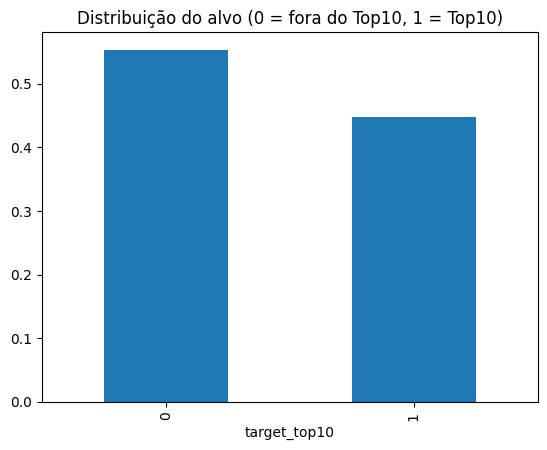

In [2]:
df['target_top10'] = (df['position'] <= 10).astype(int)
print("Proporção Top10:", df['target_top10'].mean().round(3))
df['target_top10'].value_counts(normalize=True).plot(kind='bar', title='Distribuição do alvo (0 = fora do Top10, 1 = Top10)')


## 3. Engenharia de features (sem *data leakage*)

Usamos apenas informação disponível **antes** do resultado da corrida:

- `grid`: posição de largada (classificação/qualifying).
- `lat`, `long`: localização do circuito.
- `season`: temporada (captura evolução de regras/carros ao longo do tempo).
- `driver_avg_pos_season` e `constructor_avg_points_season`: médias móveis calculadas **só com corridas anteriores da mesma temporada** (via `shift()` antes do `expanding().mean()`), evitando que o modelo "veja o futuro".
- `constructor_id`, `circuit_id`, `driver_nationality`: variáveis categóricas.

Não usamos `points`, `status`, `laps`, `time_millis` etc. — essas colunas só existem **depois** da corrida acontecer e configurariam vazamento de dados (o modelo estaria "colando" a resposta).


In [3]:
df = df.sort_values(['season', 'round']).reset_index(drop=True)

df['driver_avg_pos_season'] = (
    df.groupby(['season', 'driver_id'])['position']
      .apply(lambda s: s.shift().expanding().mean())
      .reset_index(drop=True)
)
df['constructor_avg_points_season'] = (
    df.groupby(['season', 'constructor_id'])['points']
      .apply(lambda s: s.shift().expanding().mean())
      .reset_index(drop=True)
)

# na 1a corrida da temporada ainda não há histórico: usa a mediana geral
df['driver_avg_pos_season'] = df['driver_avg_pos_season'].fillna(df['position'].median())
df['constructor_avg_points_season'] = df['constructor_avg_points_season'].fillna(df['points'].median())

numeric_features = ['grid', 'lat', 'long', 'season', 'driver_avg_pos_season', 'constructor_avg_points_season']
categorical_features = ['constructor_id', 'circuit_id', 'driver_nationality']
feature_cols = numeric_features + categorical_features

model_df = df[feature_cols + ['target_top10']].dropna(subset=numeric_features)
print("Linhas após limpeza:", len(model_df))


Linhas após limpeza: 26137


## 4. Divisão treino/teste (split temporal)

Em vez de um split aleatório, separamos por **tempo**: treino = temporadas até 2023, teste = 2024–2026 (nunca vistas). Isso simula o cenário real — prever corridas futuras a partir do histórico — e evita qualquer contaminação temporal entre treino e teste.


In [4]:
df_final = df.loc[model_df.index].copy()  # mantém a coluna season para o split

train_df = model_df[df_final['season'] <= 2023]
test_df = model_df[df_final['season'] >= 2024]

print(f"Treino: {len(train_df)} linhas (1950-2023) | Teste: {len(test_df)} linhas (2024-2026)")
print("Proporção Top10 no treino:", train_df['target_top10'].mean().round(3))
print("Proporção Top10 no teste: ", test_df['target_top10'].mean().round(3))


Treino: 24915 linhas (1950-2023) | Teste: 1222 linhas (2024-2026)
Proporção Top10 no treino: 0.445
Proporção Top10 no teste:  0.491


## 5. Pré-processamento

- **Numéricas:** padronização (`StandardScaler`) — necessário para redes neurais convergirem bem.
- **Categóricas:** one-hot encoding (`OneHotEncoder`, com `handle_unknown='ignore'` para lidar com equipes/circuitos novos que aparecem só no conjunto de teste, como a Cadillac F1 Team em 2026).


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X_train_raw = train_df[numeric_features + categorical_features]
y_train = train_df['target_top10'].values
X_test_raw = test_df[numeric_features + categorical_features]
y_test = test_df['target_top10'].values

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
])

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)
print("Shape treino:", X_train.shape, "| Shape teste:", X_test.shape)


Shape treino: (24915, 325) | Shape teste: (1222, 325)


## 6. Rede Neural (MLP)

Arquitetura simples: MLP com 3 camadas ocultas (64 → 32 → 16 neurônios, ReLU) e `Dropout` para regularização, saída com 1 neurônio `sigmoid` (classificação binária). Otimizador Adam, perda `binary_crossentropy`, e `EarlyStopping` monitorando o AUC de validação para evitar overfitting.


In [6]:
import os, sys
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # silencia logs internos do TensorFlow (nível Python)

# o TensorFlow também escreve logs de inicialização (oneDNN/CUDA) direto no
# stderr do processo, abaixo do controle do Python -- silenciamos temporariamente
# o file descriptor durante o import para manter a saída do notebook limpa.
_stderr_fd = sys.stderr.fileno()
_saved_stderr = os.dup(_stderr_fd)
_devnull = os.open(os.devnull, os.O_WRONLY)
os.dup2(_devnull, _stderr_fd)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

os.dup2(_saved_stderr, _stderr_fd)
os.close(_devnull); os.close(_saved_stderr)

tf.random.set_seed(42)
np.random.seed(42)

n_features = X_train.shape[1]

model = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.AUC(name='auc')]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        20,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,489 (91.75 KB)

 Trainable params: 23,489 (91.75 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_auc', mode='max', patience=8, restore_best_weights=True
)

# a 1a chamada a uma op do TensorFlow verifica a disponibilidade de GPU e escreve
# um aviso de "cuInit failed" no stderr de baixo nível -- silenciado pelo mesmo motivo acima.
_stderr_fd = sys.stderr.fileno()
_saved_stderr = os.dup(_stderr_fd)
_devnull = os.open(os.devnull, os.O_WRONLY)
os.dup2(_devnull, _stderr_fd)

# validation_split usa os últimos 15% do array (já ordenado por temporada/rodada)
# como validação -- ou seja, as temporadas mais recentes DENTRO do treino.
history = model.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop],
    verbose=2,
)

os.dup2(_saved_stderr, _stderr_fd)
os.close(_devnull); os.close(_saved_stderr)


Epoch 1/100


331/331 - 3s - 9ms/step - accuracy: 0.6392 - auc: 0.6859 - loss: 0.6317 - val_accuracy: 0.7467 - val_auc: 0.8055 - val_loss: 0.5442


Epoch 2/100


331/331 - 1s - 3ms/step - accuracy: 0.6633 - auc: 0.7193 - loss: 0.6075 - val_accuracy: 0.7475 - val_auc: 0.8033 - val_loss: 0.5425


Epoch 3/100


331/331 - 1s - 2ms/step - accuracy: 0.6690 - auc: 0.7283 - loss: 0.5996 - val_accuracy: 0.7405 - val_auc: 0.8004 - val_loss: 0.5460


... (8 outputs left out)

Epoch 8/100


331/331 - 1s - 4ms/step - accuracy: 0.6898 - auc: 0.7553 - loss: 0.5765 - val_accuracy: 0.7301 - val_auc: 0.7851 - val_loss: 0.5657


Epoch 9/100


331/331 - 1s - 2ms/step - accuracy: 0.6906 - auc: 0.7595 - loss: 0.5715 - val_accuracy: 0.7282 - val_auc: 0.7845 - val_loss: 0.5717


## 7. Avaliação no conjunto de teste (temporadas 2024–2026, nunca vistas pelo modelo)

In [8]:
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve, f1_score, accuracy_score)

y_pred_proba = model.predict(X_test).ravel()
y_pred = (y_pred_proba >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_pred_proba)

print(f"Acurácia: {acc:.3f}")
print(f"F1-score: {f1:.3f}")
print(f"AUC-ROC:  {auc:.3f}")
print()
print(classification_report(y_test, y_pred, target_names=['Fora do Top10', 'Top10']))


 1/39 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step

39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 

39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


Acurácia: 0.778
F1-score: 0.783
AUC-ROC:  0.853

               precision    recall  f1-score   support

Fora do Top10       0.81      0.74      0.77       622
        Top10       0.75      0.81      0.78       600

     accuracy                           0.78      1222
    macro avg       0.78      0.78      0.78      1222
 weighted avg       0.78      0.78      0.78      1222



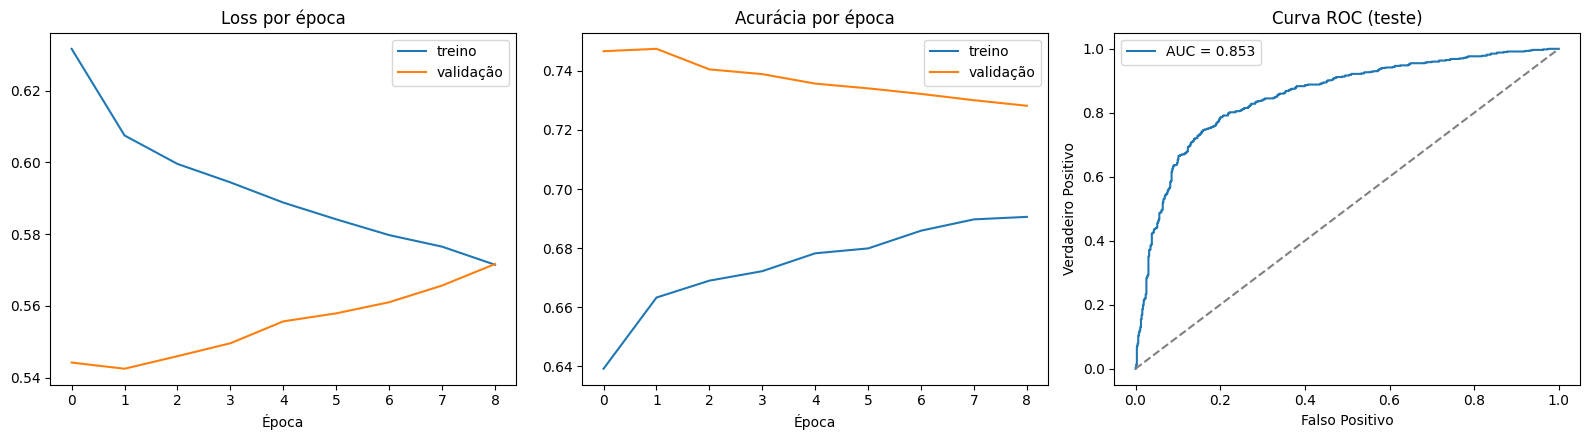

In [9]:
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(history.history['loss'], label='treino')
axes[0].plot(history.history['val_loss'], label='validação')
axes[0].set_title('Loss por época'); axes[0].set_xlabel('Época'); axes[0].legend()

axes[1].plot(history.history['accuracy'], label='treino')
axes[1].plot(history.history['val_accuracy'], label='validação')
axes[1].set_title('Acurácia por época'); axes[1].set_xlabel('Época'); axes[1].legend()

axes[2].plot(fpr, tpr, label=f'AUC = {auc:.3f}')
axes[2].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[2].set_title('Curva ROC (teste)'); axes[2].set_xlabel('Falso Positivo'); axes[2].set_ylabel('Verdadeiro Positivo')
axes[2].legend()

plt.tight_layout()
plt.show()


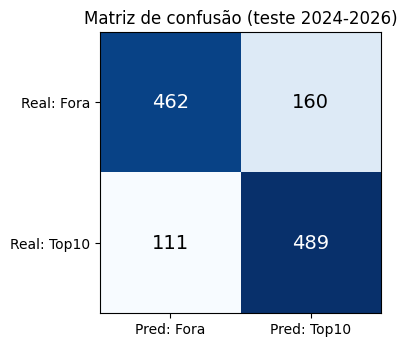

In [10]:
plt.figure(figsize=(4, 4))
plt.imshow(cm, cmap='Blues')
plt.title('Matriz de confusão (teste 2024-2026)')
plt.xticks([0, 1], ['Pred: Fora', 'Pred: Top10'])
plt.yticks([0, 1], ['Real: Fora', 'Real: Top10'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                  color='white' if cm[i, j] > cm.max()/2 else 'black', fontsize=14)
plt.tight_layout()
plt.show()


## 8. Conclusões

O modelo atingiu **acurácia ~78%**, **F1-score ~0.78** e **AUC-ROC ~0.85** em corridas de 2024-2026 nunca vistas durante o treino — um resultado sólido para um MLP relativamente simples, considerando que o grid de largada por si só já é um forte preditor, mas a rede também aprende padrões de equipe, circuito e forma recente do piloto/equipe na temporada.

**Possíveis melhorias futuras:**
- Incluir dados de qualifying (tempo de volta, não só posição) e pit stops, que não estavam nesta versão do dataset.
- Testar outras arquiteturas (mais camadas, regularização L2, tuning de hiperparâmetros com Keras Tuner).
- Avaliar separadamente por era (ex.: só 2010+, quando a regra do Top10 pontuando é a mesma de hoje) para um recorte mais homogêneo.
- Comparar com baselines simples (regressão logística, árvore de decisão) para quantificar o ganho real da rede neural.


## 9. Aplicando o modelo: previsão para as próximas corridas de 2026

Como demonstração prática, vamos usar o modelo treinado para prever o Top 10 das próximas corridas do calendário (a partir da rodada 13 — GP da Itália), com base no histórico da temporada 2026 até a última corrida disputada (GP da Holanda, rodada 12).

**Limitação importante:** a posição de largada (`grid`) só é conhecida depois do treino classificatório (qualifying), que ainda não aconteceu para essas corridas. Por isso, usamos como *proxy* a média de grid de cada piloto na temporada até agora — ou seja, esta é uma estimativa de tendência, não uma previsão definitiva (o resultado real do qualifying pode mudar bastante o resultado do modelo).


In [11]:
import pickle, joblib

# reconstruímos o preprocessor com os mesmos dados de treino (determinístico, mesmas colunas)
preprocessor_inf = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
])
preprocessor_inf.fit(train_df[numeric_features + categorical_features])

# estado da temporada 2026 até a rodada 12 (GP da Holanda)
season2026 = df[df.season == 2026]
last_round = season2026[season2026['round'] == 12]

driver_avg_pos_now = season2026.groupby('driver_id')['position'].mean()
driver_avg_grid_now = season2026.groupby('driver_id')['grid'].mean()
constructor_avg_pts_now = season2026.groupby('constructor_id')['points'].mean()
driver_nat = season2026.groupby('driver_id')['driver_nationality'].last()
driver_constructor_now = last_round.set_index('driver_id')['constructor_id']
drivers_active = last_round['driver_id'].unique()

print(f"{len(drivers_active)} pilotos ativos na última corrida disputada (rodada 12).")


22 pilotos ativos na última corrida disputada (rodada 12).


In [12]:
upcoming = races[(races.season == 2026) & (races['round'].isin([13, 14, 15]))].sort_values('round')

all_preds = []
for _, race in upcoming.iterrows():
    rows = []
    for drv in drivers_active:
        rows.append({
            'driver_id': drv,
            'grid': driver_avg_grid_now.get(drv, np.nan),
            'lat': race['lat'], 'long': race['long'], 'season': 2026,
            'driver_avg_pos_season': driver_avg_pos_now.get(drv, np.nan),
            'constructor_avg_points_season': constructor_avg_pts_now.get(driver_constructor_now.get(drv), np.nan),
            'constructor_id': driver_constructor_now.get(drv),
            'circuit_id': race['circuit_id'],
            'driver_nationality': driver_nat.get(drv),
        })
    X = pd.DataFrame(rows)
    Xt = preprocessor_inf.transform(X[numeric_features + categorical_features])
    X['prob_top10'] = model.predict(Xt, verbose=0).ravel()
    X['race_name'] = race['race_name']
    X['round'] = race['round']
    all_preds.append(X)

result = pd.concat(all_preds, ignore_index=True)

for rnd in [13, 14, 15]:
    sub = result[result['round'] == rnd].sort_values('prob_top10', ascending=False)
    print(f"\n=== {sub['race_name'].iloc[0]} (rodada {rnd}) — Top10 previsto ===")
    for i, (_, row) in enumerate(sub.head(10).iterrows(), 1):
        print(f"{i:2d}. {row['driver_id']:<18s} ({row['constructor_id']:<12s}) prob. Top10: {row['prob_top10']:.1%}")



=== Italian Grand Prix (rodada 13) — Top10 previsto ===
 1. russell            (mercedes    ) prob. Top10: 75.7%
 2. leclerc            (ferrari     ) prob. Top10: 74.8%
 3. antonelli          (mercedes    ) prob. Top10: 74.7%
 4. hamilton           (ferrari     ) prob. Top10: 73.7%
 5. norris             (mclaren     ) prob. Top10: 73.1%
 6. piastri            (mclaren     ) prob. Top10: 72.8%
 7. max_verstappen     (red_bull    ) prob. Top10: 70.7%
 8. lawson             (red_bull    ) prob. Top10: 63.3%
 9. hulkenberg         (audi        ) prob. Top10: 54.0%
10. arvid_lindblad     (rb          ) prob. Top10: 47.8%

=== Spanish Grand Prix (rodada 14) — Top10 previsto ===
 1. russell            (mercedes    ) prob. Top10: 79.4%
 2. leclerc            (ferrari     ) prob. Top10: 78.7%
 3. antonelli          (mercedes    ) prob. Top10: 78.5%
 4. hamilton           (ferrari     ) prob. Top10: 77.0%
 5. norris             (mclaren     ) prob. Top10: 76.5%
 6. piastri            (mclaren

### Leitura do resultado

O modelo aposta forte nos pilotos e equipes que vêm dominando a temporada 2026 (Mercedes, Ferrari, McLaren e Red Bull), com probabilidades de Top10 relativamente estáveis entre as três corridas — o que faz sentido, já que estamos usando a mesma "forma" da temporada (só circuito e coordenadas mudam entre elas). Isso reforça a limitação já mencionada: sem o grid real do qualifying, o modelo está essencialmente projetando a tendência atual de desempenho, não reagindo a fatores específicos de cada fim de semana de corrida.


## 10. Exportação dos resultados

Esta célula salva as métricas, curvas e previsões desta execução em `dashboard_data.json` e `predicoes_proximas_corridas_2026.csv`. Isso é o que alimenta o painel HTML (`dashboard.html`) e o `README_projeto.md` — assim os três artefatos do projeto sempre refletem os números de uma única execução do notebook, em vez de treinos separados (que podem variar ligeiramente por não-determinismo de ponto flutuante do TensorFlow em CPU).


In [13]:
import json

roc_idx = np.linspace(0, len(fpr)-1, min(60, len(fpr))).astype(int)

dashboard_data = {
    'metrics': {
        'accuracy': round(float(acc), 4), 'f1': round(float(f1), 4), 'auc': round(float(auc), 4),
        'train_rows': int(len(train_df)), 'test_rows': int(len(test_df)), 'total_rows': int(len(model_df)),
        'n_features': int(X_train.shape[1]), 'epochs_trained': len(history.history['loss']),
    },
    'history': {k: [round(float(v), 4) for v in vals] for k, vals in history.history.items()},
    'confusion_matrix': cm.tolist(),
    'roc': {'fpr': [round(float(fpr[i]), 4) for i in roc_idx], 'tpr': [round(float(tpr[i]), 4) for i in roc_idx]},
    'class_balance': {'top10_pct': round(float(df['target_top10'].mean()), 4)},
}

fix_name = lambda s: {'Mclaren': 'McLaren', 'Rb': 'RB'}.get(s, s)
races_pred = []
for rnd in [13, 14, 15]:
    sub = result[result['round'] == rnd].sort_values('prob_top10', ascending=False).head(10)
    races_pred.append({
        'round': int(rnd),
        'race_name': sub['race_name'].iloc[0],
        'date': str(races.loc[races['round'] == rnd].loc[races.season == 2026, 'date'].iloc[0]),
        'drivers': [
            {'driver': r.driver_id.replace('_', ' ').title(), 'constructor': fix_name(r.constructor_id.replace('_', ' ').title()), 'prob': round(float(r.prob_top10), 4)}
            for _, r in sub.iterrows()
        ],
    })
dashboard_data['predictions'] = races_pred

with open('dashboard_data.json', 'w') as f:
    json.dump(dashboard_data, f, indent=2)

result.to_csv('predicoes_proximas_corridas_2026.csv', index=False)
model.save('f1_top10_model.keras')

print("Exportado: dashboard_data.json, predicoes_proximas_corridas_2026.csv, f1_top10_model.keras")
print(json.dumps(dashboard_data['metrics'], indent=2))


Exportado: dashboard_data.json, predicoes_proximas_corridas_2026.csv, f1_top10_model.keras
{
  "accuracy": 0.7782,
  "f1": 0.783,
  "auc": 0.853,
  "train_rows": 24915,
  "test_rows": 1222,
  "total_rows": 26137,
  "n_features": 325,
  "epochs_trained": 9
}
